# Fase 3 · XGBoost por región y SHAP

Un modelo por departamento y horizonte (*h* = 1 a 4 semanas), usando solo información disponible en *T − h*:

| Modelo | Variables |
|---|---|
| **XGBoost sin clima** | Casos rezagados (*T − h* a *T − h − 3*) y estacionalidad de la semana objetivo |
| **XGBoost con clima** | Lo anterior + clima rezagado (*T − h* a *T − h − 3*) + ICEN conocido en *T − h* |
| **XGBoost con clima, rezagos hasta 12** | Prueba de sensibilidad con rezagos de clima más largos |

Comparar *con clima* contra *sin clima* responde la **hipótesis H2**: si el clima no mejora al modelo que ya tiene los casos pasados, no está aportando. SHAP agrupado por categoría responde la **hipótesis H1** (¿los factores climáticos cambian por región?).

- **Selección de variables** (como el artículo de referencia): por categoría (temperatura, lluvia, humedad, viento, ICEN), la variable más correlacionada (|Spearman|) con log1p(casos), calculada **solo con entrenamiento**.
- **Hiperparámetros:** profundidad, `min_child_weight` y objetivo, elegidos por MAE en validación (2022–2023) con parada temprana. Para la prueba se reentrena con 2010–2023.
- **Objetivo "delta":** los árboles no extrapolan fuera del rango de entrenamiento, así que además del nivel de casos (`log`, `poisson`) se prueba predecir el **cambio** respecto a *T − h*. La validación lo eligió en el 92 % de los modelos.
- **SHAP muestra lo que usa el modelo, no causalidad.**

⏱️ La celda de modelado tarda unos **15 minutos** (17 departamentos × 4 horizontes × 3 variantes × 18 configuraciones).

**Entradas:** `data/processed/panel_depto_semana.parquet` y `data/processed/predicciones_lineas_base.parquet` (notebook 08).

## Configuración

In [1]:
# Rutas: el notebook funciona desde la raiz del proyecto o desde notebooks/
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))  # para importar scripts/comun.py

In [2]:
import itertools
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

from comun import (ENTRENAMIENTO, EXCLUIR_MODELO, HORIZONTES, MIN_CASOS_TRAIN, PRUEBA, REGIONES,
                   VALIDACION)

PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs"
SEMILLA = 42

N_REZAGOS = 4                 # rezagos h .. h + 3 (casos y clima)
MAX_REZAGO_SENSIBILIDAD = 12  # rezagos h .. 12 en la prueba de sensibilidad
CATEGORIAS = {
    "temperatura": ["temp_media", "temp_max", "temp_min", "rango_term"],
    "lluvia": ["precip_total", "precip_max_d", "dias_lluvia"],
    "humedad": ["hum_rel"],
    "viento": ["viento"],
}
ICEN = ["icen_lag3", "icen_lag4", "icen_lag5", "icen_lag6"]
REJILLA = [
    {"max_depth": d, "min_child_weight": m, "objetivo": o}
    for d, m, o in itertools.product([2, 3, 4], [1, 5], ["log", "poisson", "delta"])
]
PARAMS_FIJOS = dict(learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                    random_state=SEMILLA, n_jobs=4)
MAX_ARBOLES, PARADA_TEMPRANA = 1000, 50

SIN_CLIMA, CON_CLIMA, CON_CLIMA_12 = "XGBoost sin clima", "XGBoost con clima", "XGBoost con clima, rezagos hasta 12"
PERSISTENCIA, REGRESION = "Persistencia", "Regresion con rezagos"

## Datos y variables rezagadas

In [3]:
panel = pd.read_parquet(PROC / "panel_depto_semana.parquet")
panel = panel.sort_values(["departamento", "ano", "semana"]).reset_index(drop=True)
panel["log_casos"] = np.log1p(panel["casos"])
panel["sem_sin"] = np.sin(2 * np.pi * panel["semana"] / 52)
panel["sem_cos"] = np.cos(2 * np.pi * panel["semana"] / 52)
g = panel.groupby("departamento", sort=False)

casos_train = panel[panel["ano"].between(*ENTRENAMIENTO)].groupby("departamento")["casos"].sum()
deptos = [d for d in casos_train[casos_train >= MIN_CASOS_TRAIN].index if d not in EXCLUIR_MODELO]
print(f"Departamentos ({len(deptos)}): {', '.join(deptos)}")

# Todos los rezagos que pueda usar cualquier horizonte (1 .. 12)
rezagos_max = max(MAX_REZAGO_SENSIBILIDAD, max(HORIZONTES) + N_REZAGOS - 1)
nuevas = {}
for k in range(1, rezagos_max + 1):
    nuevas[f"casos_l{k}"] = g["log_casos"].shift(k)
    for v in itertools.chain.from_iterable(CATEGORIAS.values()):
        nuevas[f"{v}_l{k}"] = g[v].shift(k)
for h in HORIZONTES:
    for c in ICEN:
        nuevas[f"{c}_s{h}"] = g[c].shift(h)  # valor conocido en la semana T - h
panel = pd.concat([panel, pd.DataFrame(nuevas)], axis=1)

Departamentos (17): AMAZONAS, ANCASH, AYACUCHO, CAJAMARCA, CUSCO, HUANUCO, ICA, JUNIN, LA LIBERTAD, LAMBAYEQUE, LORETO, MADRE DE DIOS, PASCO, PIURA, SAN MARTIN, TUMBES, UCAYALI


## Funciones: variables candidatas, selección por categoría y modelo

In [4]:
def candidatas(h: int, ultimo_rezago: int) -> dict[str, dict[str, list[str]]]:
    """Columnas candidatas por categoria y variable para el horizonte h."""
    rezagos = range(h, ultimo_rezago + 1)
    cand = {cat: {v: [f"{v}_l{k}" for k in rezagos] for v in vs} for cat, vs in CATEGORIAS.items()}
    cand["icen"] = {c: [f"{c}_s{h}"] for c in ICEN}
    return cand


def seleccionar(train: pd.DataFrame, cand: dict) -> tuple[list[str], list[dict]]:
    """Por categoria, la variable con mayor |Spearman| (en alguno de sus rezagos) con log1p(casos)."""
    columnas, registro = [], []
    for cat, variables in cand.items():
        todas = [c for cols in variables.values() for c in cols]
        corr = train[todas].corrwith(train["log_casos"], method="spearman").abs()
        mejor_var = max(variables, key=lambda v: corr[variables[v]].max())
        columnas += variables[mejor_var]
        registro.append({"categoria": cat, "variable": mejor_var,
                         "rezago_mas_correlacionado": corr[variables[mejor_var]].idxmax(),
                         "abs_spearman": round(float(corr[variables[mejor_var]].max()), 3)})
    return columnas, registro


def modelo_xgb(config: dict, n_arboles: int, parada: bool) -> XGBRegressor:
    objetivo = "count:poisson" if config["objetivo"] == "poisson" else "reg:squarederror"
    extra = {"early_stopping_rounds": PARADA_TEMPRANA} if parada else {}
    return XGBRegressor(n_estimators=n_arboles, max_depth=config["max_depth"],
                        min_child_weight=config["min_child_weight"], objective=objetivo,
                        **PARAMS_FIJOS, **extra)


def objetivo_de(config: dict, df: pd.DataFrame, h: int) -> pd.Series:
    if config["objetivo"] == "log":
        return df["log_casos"]
    if config["objetivo"] == "delta":
        return df["log_casos"] - df[f"casos_l{h}"]
    return df["casos"]


def a_casos(config: dict, pred: np.ndarray, df: pd.DataFrame, h: int) -> np.ndarray:
    if config["objetivo"] == "log":
        casos = np.expm1(pred)
    elif config["objetivo"] == "delta":
        casos = np.expm1(df[f"casos_l{h}"].to_numpy() + pred)
    else:
        casos = pred
    return np.clip(casos, 0, None)


def metricas(y, p) -> dict:
    return {"rmse": float(np.sqrt(mean_squared_error(y, p))), "mae": float(mean_absolute_error(y, p)),
            "r2": float(r2_score(y, p))}

## Modelado: selección de variables, hiperparámetros, prueba y SHAP

In [5]:
filas_met, filas_sel, filas_shap, predicciones = [], [], [], []
inicio = time.time()
for depto in deptos:
    d = panel[panel["departamento"] == depto]
    for h in HORIZONTES:
        base = [f"casos_l{k}" for k in range(h, h + N_REZAGOS)] + ["sem_sin", "sem_cos"]
        en_train = d["ano"].between(*ENTRENAMIENTO)
        train = d[en_train].dropna(subset=base)
        clima_4, sel_4 = seleccionar(train, candidatas(h, h + N_REZAGOS - 1))
        clima_12, sel_12 = seleccionar(train, candidatas(h, MAX_REZAGO_SENSIBILIDAD))
        variantes = {SIN_CLIMA: base, CON_CLIMA: base + clima_4}
        if h <= MAX_REZAGO_SENSIBILIDAD - N_REZAGOS + 1:
            variantes[CON_CLIMA_12] = base + clima_12
        for nombre, sel in [(CON_CLIMA, sel_4), (CON_CLIMA_12, sel_12)]:
            filas_sel += [{"departamento": depto, "horizonte": h, "modelo": nombre, **s} for s in sel]

        for nombre, cols in variantes.items():
            tr = d[en_train].dropna(subset=cols)
            va = d[d["ano"].between(*VALIDACION)]
            te = d[d["ano"].between(*PRUEBA)]
            tr_va = d[d["ano"].between(ENTRENAMIENTO[0], VALIDACION[1])].dropna(subset=cols)
            assert va[cols].notna().all().all() and te[cols].notna().all().all()

            # 1) Elegir hiperparametros en validacion
            mejor = None
            for config in REJILLA:
                m = modelo_xgb(config, MAX_ARBOLES, parada=True)
                m.fit(tr[cols], objetivo_de(config, tr, h),
                      eval_set=[(va[cols], objetivo_de(config, va, h))], verbose=False)
                p_va = a_casos(config, m.predict(va[cols]), va, h)
                mae = mean_absolute_error(va["casos"], p_va)
                if mejor is None or mae < mejor[0]:
                    mejor = (mae, config, m.best_iteration + 1, p_va)
            _, config, n_arboles, p_va = mejor

            # 2) Reentrenar con entrenamiento + validacion y evaluar en prueba
            final = modelo_xgb(config, n_arboles, parada=False)
            final.fit(tr_va[cols], objetivo_de(config, tr_va, h), verbose=False)
            p_te = a_casos(config, final.predict(te[cols]), te, h)

            for conjunto, df, p in [("Validacion", va, p_va), ("Prueba", te, p_te)]:
                filas_met.append({"conjunto": conjunto, "departamento": depto, "horizonte": h,
                                  "modelo": nombre, **metricas(df["casos"], p),
                                  "objetivo": config["objetivo"], "max_depth": config["max_depth"],
                                  "min_child_weight": config["min_child_weight"], "n_arboles": n_arboles,
                                  "n_variables": len(cols)})
                predicciones.append(pd.DataFrame({
                    "conjunto": conjunto, "departamento": depto, "ano": df["ano"].to_numpy(),
                    "semana": df["semana"].to_numpy(), "fecha": df["fecha"].to_numpy(), "horizonte": h,
                    "modelo": nombre, "casos": df["casos"].to_numpy(), "prediccion": p}))

            # 3) SHAP del modelo final con clima (rezagos h .. h+3)
            if nombre == CON_CLIMA:
                valores = shap.TreeExplainer(final).shap_values(tr_va[cols])
                importancia = np.abs(valores).mean(axis=0)
                for col, imp in zip(cols, importancia):
                    if col.startswith("casos_l"):
                        cat = "casos pasados"
                    elif col.startswith("sem_"):
                        cat = "estacionalidad"
                    elif col.startswith("icen"):
                        cat = "icen"
                    else:
                        cat = next(c for c, vs in CATEGORIAS.items() if col.rsplit("_l", 1)[0] in vs)
                    filas_shap.append({"departamento": depto, "horizonte": h, "variable": col,
                                       "categoria": cat, "importancia": float(imp)})
    print(f"  {depto:15s} listo ({time.time() - inicio:,.0f} s)")

  AMAZONAS        listo (46 s)


  ANCASH          listo (85 s)


  AYACUCHO        listo (102 s)


  CAJAMARCA       listo (129 s)


  CUSCO           listo (157 s)


  HUANUCO         listo (184 s)


... (7 outputs left out)

  PIURA           listo (551 s)


  SAN MARTIN      listo (579 s)


  TUMBES          listo (631 s)


  UCAYALI         listo (670 s)


## Líneas base en las mismas semanas

In [6]:
base_pred = pd.read_parquet(PROC / "predicciones_lineas_base.parquet")
for (conjunto, depto, h), df in base_pred[base_pred["departamento"].isin(deptos)].groupby(
        ["conjunto", "departamento", "horizonte"]):
    for nombre, col in [(PERSISTENCIA, "pred_persistencia"), (REGRESION, "pred_regresion")]:
        filas_met.append({"conjunto": conjunto, "departamento": depto, "horizonte": h, "modelo": nombre,
                          **metricas(df["casos"], df[col])})

metricas_df = pd.DataFrame(filas_met)
metricas_df.to_csv(OUT / "fase3_metricas.csv", index=False, float_format="%.4f")
pd.DataFrame(filas_sel).to_csv(OUT / "fase3_variables_seleccionadas.csv", index=False)
shap_df = pd.DataFrame(filas_shap)
shap_df["pct"] = shap_df["importancia"] / shap_df.groupby(["departamento", "horizonte"])["importancia"].transform("sum") * 100
shap_df.to_csv(OUT / "fase3_shap_importancia.csv", index=False, float_format="%.5f")
pd.concat(predicciones, ignore_index=True).to_parquet(PROC / "predicciones_xgboost.parquet", index=False)

## Resumen de resultados

In [7]:
pd.set_option("display.width", 200)
orden = [PERSISTENCIA, REGRESION, SIN_CLIMA, CON_CLIMA, CON_CLIMA_12]
for conjunto in ["Validacion", "Prueba"]:
    sub = metricas_df[(metricas_df["conjunto"] == conjunto) & metricas_df["departamento"].isin(REGIONES)]
    tabla = sub.pivot_table(index=["departamento", "modelo"], columns="horizonte", values="r2")
    tabla = tabla.reindex([(d, m) for d in REGIONES for m in orden])
    print(f"\n{conjunto}: R2 en las regiones principales")
    print(tabla.round(3).to_string())

print("\nH2: departamentos donde 'con clima' tiene menor MAE que 'sin clima'")
for conjunto in ["Validacion", "Prueba"]:
    sub = metricas_df[metricas_df["conjunto"] == conjunto].pivot_table(
        index=["departamento", "horizonte"], columns="modelo", values="mae")
    gana = (sub[CON_CLIMA] < sub[SIN_CLIMA]).groupby(level="horizonte").agg(["sum", "size"])
    mejora = ((sub[SIN_CLIMA] - sub[CON_CLIMA]) / sub[SIN_CLIMA] * 100).groupby(level="horizonte").median()
    print(f"  {conjunto}: " + "; ".join(f"h={h}: {int(r['sum'])}/{int(r['size'])} (mediana {mejora[h]:+.1f} % MAE)"
                                       for h, r in gana.iterrows()))

cat_clima = ["temperatura", "lluvia", "humedad", "viento", "icen"]
por_cat = shap_df.groupby(["departamento", "horizonte", "categoria"])["pct"].sum().unstack(fill_value=0)
print("\nSHAP, h = 2: % de la importancia total por categoria")
print(por_cat.xs(2, level="horizonte").loc[deptos].round(1).to_string())


Validacion: R2 en las regiones principales
horizonte                                             1      2      3      4
departamento modelo                                                         
PIURA        Persistencia                         0.916  0.765  0.540  0.319
             Regresion con rezagos                0.870  0.731  0.558  0.402
             XGBoost sin clima                    0.929  0.818  0.662  0.483
             XGBoost con clima                    0.921  0.853  0.757  0.679
             XGBoost con clima, rezagos hasta 12  0.918  0.850  0.772  0.726
LORETO       Persistencia                         0.816  0.658  0.472  0.223
             Regresion con rezagos                0.812  0.647  0.463  0.266
             XGBoost sin clima                    0.840  0.718  0.597  0.418
             XGBoost con clima                    0.830  0.712  0.678  0.620
             XGBoost con clima, rezagos hasta 12  0.836  0.707  0.676  0.670
SAN MARTIN   Persistencia       

## Gráficos

In [8]:
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
TINTA, TINTA_2, REJ = "#0b0b0b", "#52514e", "#e1e0d9"
COLORES = {PERSISTENCIA: AQUA, REGRESION: AMARILLO, SIN_CLIMA: MAGENTA, CON_CLIMA: AZUL, CON_CLIMA_12: NARANJA}


def estilo(ax):
    ax.grid(color=REJ, lw=0.6)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)

### R2 en prueba por horizonte, regiones principales

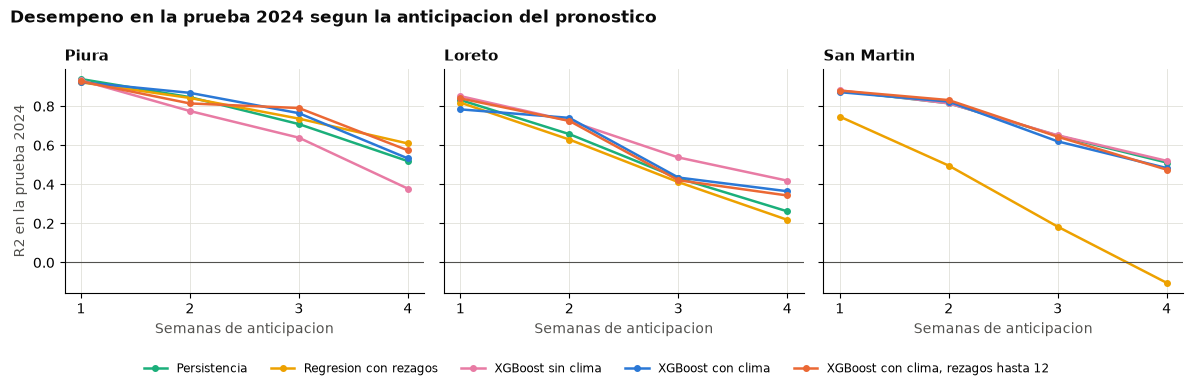

In [9]:
fig, ejes = plt.subplots(1, len(REGIONES), figsize=(12, 3.8), sharey=True)
prueba = metricas_df[metricas_df["conjunto"] == "Prueba"]
for ax, depto in zip(ejes, REGIONES):
    for modelo in orden:
        s = prueba[(prueba["departamento"] == depto) & (prueba["modelo"] == modelo)].sort_values("horizonte")
        ax.plot(s["horizonte"], s["r2"], marker="o", ms=4, lw=1.8, color=COLORES[modelo], label=modelo)
    ax.set_title(depto.title(), loc="left", fontsize=11, fontweight="bold", color=TINTA)
    ax.set_xticks(HORIZONTES)
    ax.set_xlabel("Semanas de anticipacion", color=TINTA_2)
    ax.axhline(0, color=TINTA_2, lw=0.8)
    estilo(ax)
ejes[0].set_ylabel("R2 en la prueba 2024", color=TINTA_2)
ejes[0].set_ylim(bottom=max(-0.5, ejes[0].get_ylim()[0]))
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=5, frameon=False, fontsize=8.5)
fig.suptitle("Desempeno en la prueba 2024 segun la anticipacion del pronostico", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=TINTA)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(OUT / "fase3_comparacion_regiones.png", dpi=120)
plt.show()

### Mapa de calor: importancia relativa de cada categoria climatica (h = 2)

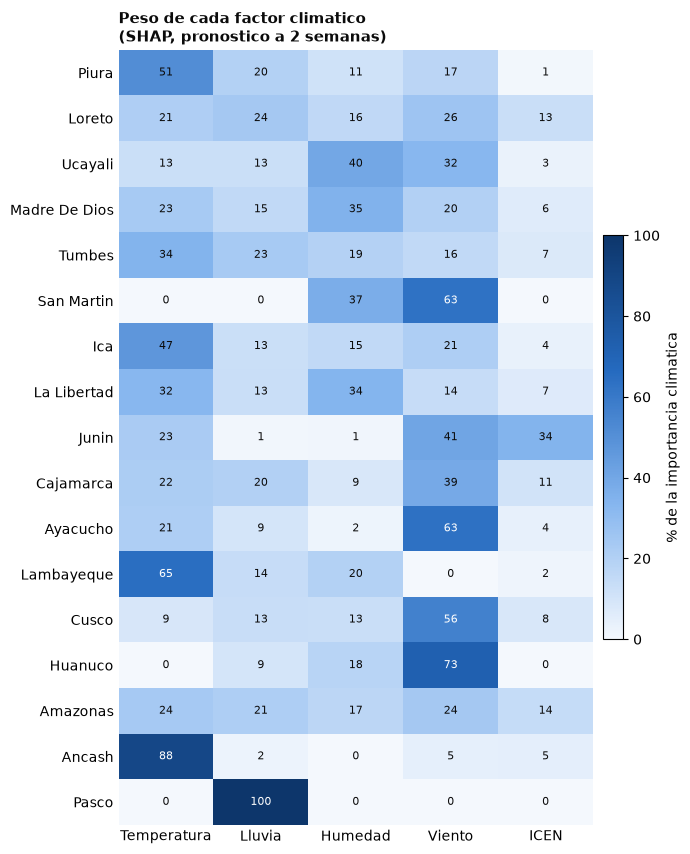

In [10]:
H_SHAP = 2
calor = por_cat.xs(H_SHAP, level="horizonte")[cat_clima]
calor = calor.div(calor.sum(axis=1), axis=0) * 100
calor = calor.loc[[d for d in casos_train.sort_values(ascending=False).index if d in calor.index]]
fig, ax = plt.subplots(figsize=(7, 0.42 * len(calor) + 1.5))
im = ax.imshow(calor.to_numpy(), cmap=matplotlib.colors.LinearSegmentedColormap.from_list(
    "azul", ["#f4f8fd", "#86b6ef", "#256abf", "#0d366b"]), vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(cat_clima)), [c.capitalize() if c != "icen" else "ICEN" for c in cat_clima])
ax.set_yticks(range(len(calor)), [d.title() for d in calor.index])
for i in range(calor.shape[0]):
    for j in range(calor.shape[1]):
        v = calor.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 55 else TINTA)
ax.set_title(f"Peso de cada factor climatico\n(SHAP, pronostico a {H_SHAP} semanas)",
             loc="left", fontsize=11, fontweight="bold", color=TINTA)
ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="% de la importancia climatica")
fig.tight_layout()
fig.savefig(OUT / "fase3_shap_categorias.png", dpi=120)
plt.show()

### Las 10 variables mas importantes por region (h = 2)

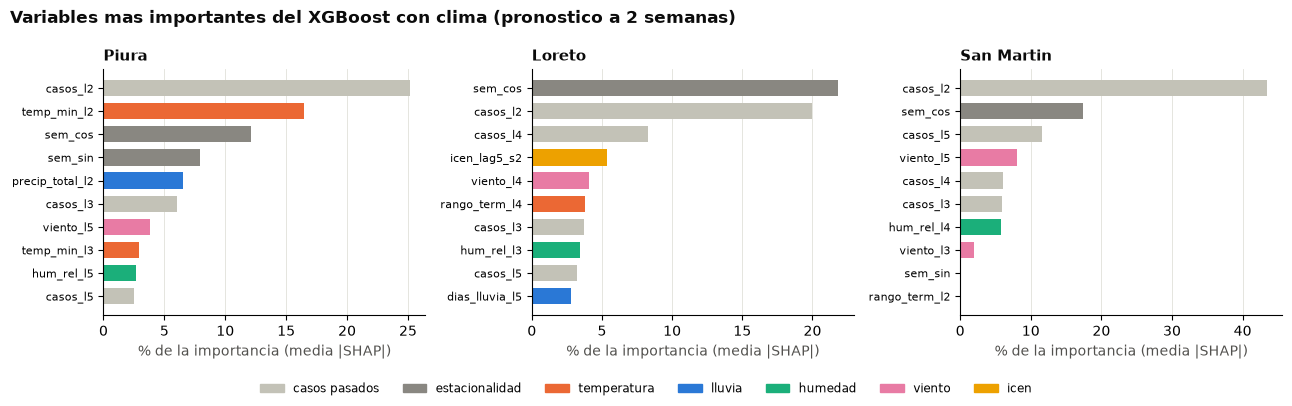


Listo en 672 s. Salidas en outputs/fase3_* y data/processed/predicciones_xgboost.parquet


In [11]:
COLOR_CAT = {"casos pasados": "#c3c2b7", "estacionalidad": "#898781", "temperatura": NARANJA,
             "lluvia": AZUL, "humedad": AQUA, "viento": MAGENTA, "icen": AMARILLO}
fig, ejes = plt.subplots(1, len(REGIONES), figsize=(13, 4))
for ax, depto in zip(ejes, REGIONES):
    s = shap_df[(shap_df["departamento"] == depto) & (shap_df["horizonte"] == H_SHAP)].nlargest(10, "pct")[::-1]
    ax.barh(s["variable"], s["pct"], color=[COLOR_CAT[c] for c in s["categoria"]], height=0.7)
    ax.set_title(depto.title(), loc="left", fontsize=11, fontweight="bold", color=TINTA)
    ax.set_xlabel("% de la importancia (media |SHAP|)", color=TINTA_2)
    ax.tick_params(axis="y", labelsize=8)
    estilo(ax)
    ax.grid(axis="y", visible=False)
manijas = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOR_CAT.values()]
fig.legend(manijas, list(COLOR_CAT), loc="lower center", ncol=7, frameon=False, fontsize=8.5)
fig.suptitle(f"Variables mas importantes del XGBoost con clima (pronostico a {H_SHAP} semanas)", x=0.01,
             ha="left", fontsize=12, fontweight="bold", color=TINTA)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(OUT / "fase3_shap_regiones_h2.png", dpi=120)
plt.show()
print(f"\nListo en {time.time() - inicio:,.0f} s. Salidas en outputs/fase3_* y data/processed/predicciones_xgboost.parquet")